In [ ]:
# STAC Figures 

# Open h5 /root/vast/eric/stac-mjx/mouse_arm_fit_new_full.h5

# Read all keys and print to cell

In [36]:
import h5py

h5_path = '/root/vast/eric/stac-mjx/mouse_arm_ik_only_new_full_copy.h5'
with h5py.File(h5_path, 'r') as f:
    keys = list(f.keys())
    print(keys)
    print(f['kp_names'][:])
    print(f"kp_data =  {f['kp_data'][:].shape}")
    print(f"xpos =  {f['xpos'][:].shape}")
    print(f['kp_data'][0,:])
    print(f['xpos'][0])
    print(f['offsets'][0])


['config', 'kp_data', 'kp_names', 'marker_sites', 'names_qpos', 'names_xpos', 'offsets', 'qpos', 'qvel', 'xpos', 'xquat']
[b'Shoulder' b'Elbow' b'Wrist']
kp_data =  (123548, 9)
xpos =  (123548, 9, 3)
[-0.02253626  0.01186064  0.06803158 -0.02969785  0.00852527  0.06331139
 -0.02941695  0.01192201  0.06327321]
[[ 0.0000000e+00  0.0000000e+00  0.0000000e+00]
 [ 0.0000000e+00  0.0000000e+00  0.0000000e+00]
 [ 0.0000000e+00  0.0000000e+00  0.0000000e+00]
 [-9.9999997e-05 -9.9999997e-05  5.0000002e-04]
 [-4.8236187e-05  4.0962518e-04 -1.7303217e-05]
 [-2.2625388e-04 -1.7008772e-03 -6.5053017e-03]
 [-2.2625388e-04 -1.7008772e-03 -6.5053017e-03]
 [-5.5708952e-05 -1.3225811e-03 -6.3312137e-03]
 [-5.5988766e-03  2.0983634e-03 -4.3136734e-03]]
[-0.00353774 -0.02170753  0.06835996]


Model points: ['world', 'ground', 'clavicle', 'scapula', 'humerus', 'ulna', 'elbow', 'radius', 'wrist_body']
Keypoints: ['Shoulder', 'Elbow', 'Wrist']

Sample data for first frame:
Original data shape: (123548, 3, 3)
Model data shape: (123548, 9, 3)

Using indices [3, 6, 8] for keypoints ['Shoulder', 'Elbow', 'Wrist']

Sample values for first frame - Original vs. Model:
Shoulder:
  Original: [-0.02253626  0.01186064  0.06803158]
  Model:    [-1.e-04 -1.e-04  5.e-04]
  Difference: [-0.02243626  0.01196064  0.06753158]
  Distance: 0.07215924673278076
Elbow:
  Original: [-0.02969785  0.00852527  0.06331139]
  Model:    [-0.00022625 -0.00170088 -0.0065053 ]
  Difference: [-0.02947159  0.01022615  0.06981669]
  Distance: 0.07646907529370821
Wrist:
  Original: [-0.02941695  0.01192201  0.06327321]
  Model:    [-0.00559888  0.00209836 -0.00431367]
  Difference: [-0.02381807  0.00982364  0.06758689]
  Distance: 0.07233112642278249


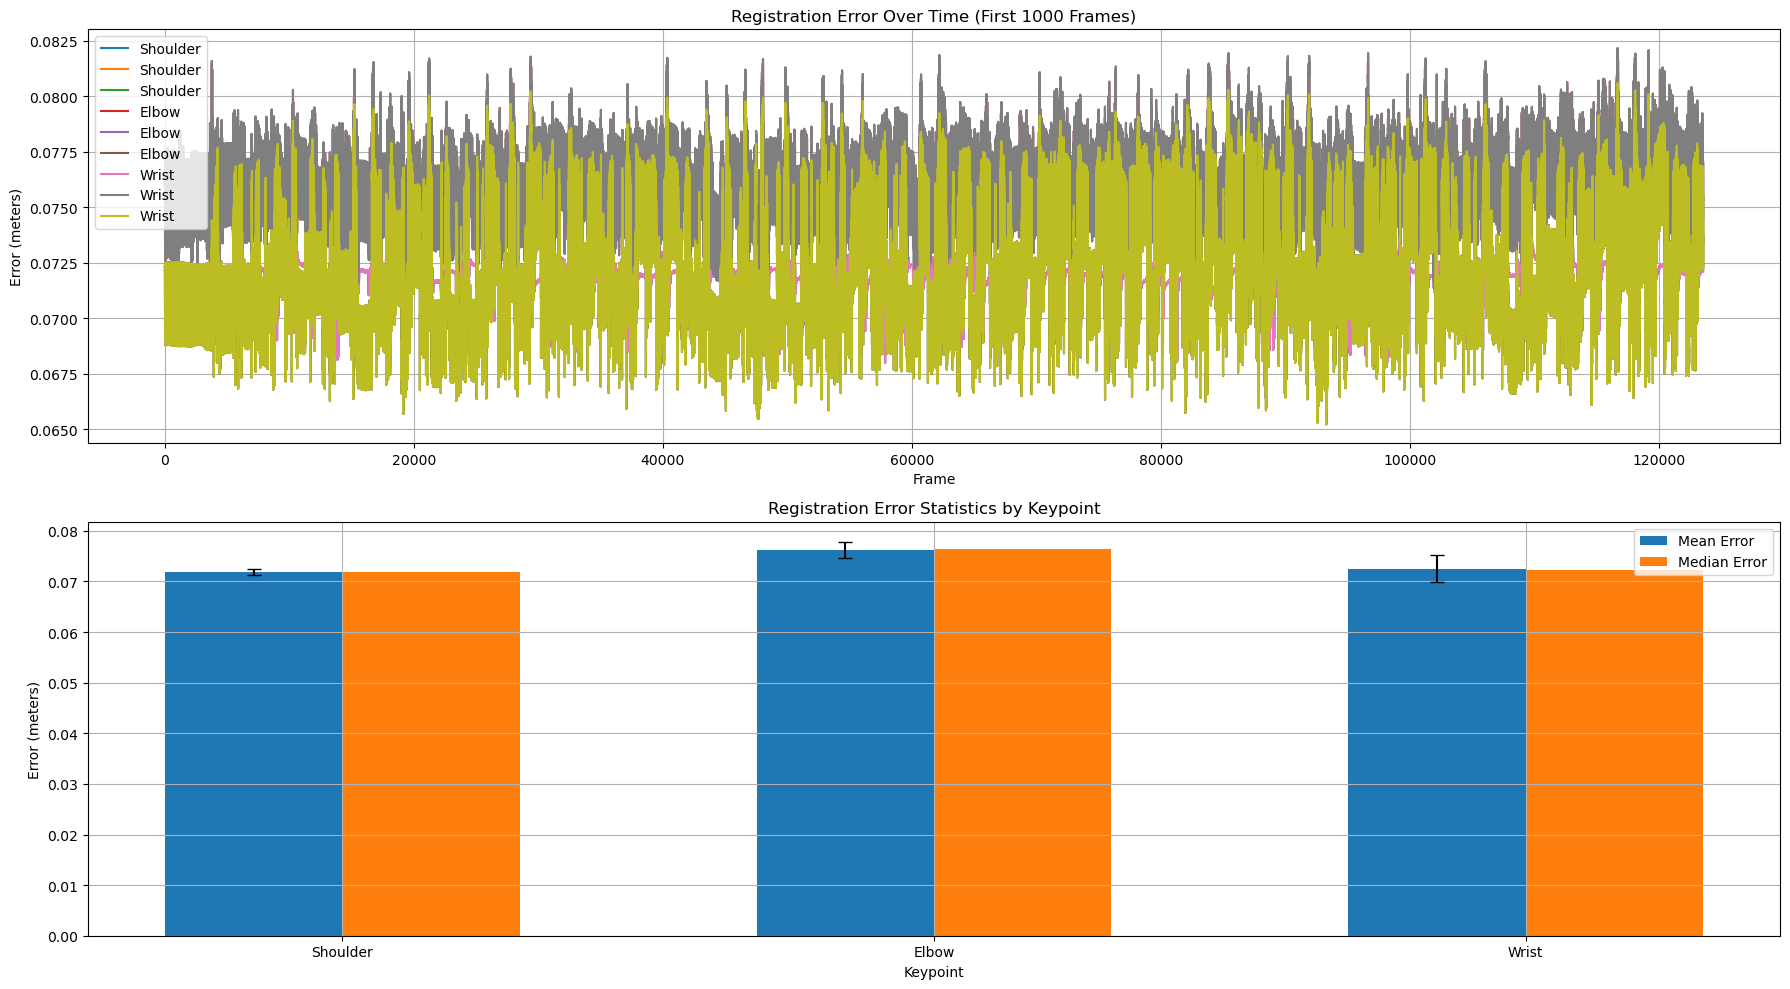


Registration Error Statistics (meters):
Shoulder: Mean = 0.07190, Median = 0.07196, Std = 0.00059
Elbow: Mean = 0.07627, Median = 0.07632, Std = 0.00162
Wrist: Mean = 0.07255, Median = 0.07227, Std = 0.00264

Overall Mean Error: 0.07358 meters


In [37]:
# Fixed registration error calculation with improved diagnostics
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import euclidean

# Load data from the H5 file
with h5py.File(h5_path, 'r') as f:
    kp_data = f['kp_data'][:]  # Original mocap data (shape: frames, 9)
    kp_names_bytes = f['kp_names'][:]  # Keypoint names
    xpos = f['xpos'][:]  # STAC model positions (shape: frames, 9, 3)
    
    # Check if we have explicit mapping information
    if 'names_xpos' in f:
        names_xpos = [name.decode('utf-8') if isinstance(name, bytes) else name 
                      for name in f['names_xpos'][:]]
        print("Model points:", names_xpos)
    
    # Convert keypoint names from bytes to strings
    kp_names = [name.decode('utf-8') for name in kp_names_bytes]
    print(f"Keypoints: {kp_names}")

# Reshape kp_data for easier comparison (frames, keypoints, xyz)
n_frames = kp_data.shape[0]
kp_data_reshaped = np.zeros((n_frames, 3, 3))
for i in range(3):  # 3 keypoints
    kp_data_reshaped[:, i, 0] = kp_data[:, i*3]     # x coordinate
    kp_data_reshaped[:, i, 1] = kp_data[:, i*3 + 1] # y coordinate
    kp_data_reshaped[:, i, 2] = kp_data[:, i*3 + 2] # z coordinate

# Display sample data to compare scales
print("\nSample data for first frame:")
print("Original data shape:", kp_data_reshaped.shape)
print("Model data shape:", xpos.shape)

keypoint_indices = [3, 6, 8]  # Shoulder, Elbow, Wrist indices in xpos
print(f"\nUsing indices {keypoint_indices} for keypoints {kp_names}")

# Print sample values to check scales
print("\nSample values for first frame - Original vs. Model:")
for i, name in enumerate(kp_names):
    model_idx = keypoint_indices[i]
    print(f"{name}:")
    print(f"  Original: {kp_data_reshaped[0, i]}")
    print(f"  Model:    {xpos[0, model_idx]}")
    print(f"  Difference: {kp_data_reshaped[0, i] - xpos[0, model_idx]}")
    print(f"  Distance: {np.sqrt(np.sum((kp_data_reshaped[0, i] - xpos[0, model_idx])**2))}")

# Calculate Euclidean distance between keypoints and model points
errors = np.zeros((n_frames, len(kp_names)))
for i in range(3):  # 3 keypoints
    model_idx = keypoint_indices[i]
    errors[:, i] = np.sqrt(np.sum((kp_data_reshaped[:, i] - xpos[:, model_idx]) ** 2, axis=1))

# Calculate summary statistics
mean_errors = np.mean(errors, axis=0)
std_errors = np.std(errors, axis=0)
median_errors = np.median(errors, axis=0)

# Create visualization
plt.figure(figsize=(18, 10))

# Plot 1: Error time series (first 1000 frames)
plt.subplot(2, 1, 1)
for i, kp_name in enumerate(kp_names):
    # Fixed: Plot only the errors for this keypoint
    plt.plot(range(len(errors)), errors, label=f'{kp_name}')
plt.xlabel('Frame')
plt.ylabel('Error (meters)')
plt.title('Registration Error Over Time (First 1000 Frames)')
plt.legend()
plt.grid(True)

# Plot 2: Error statistics by keypoint
plt.subplot(2, 1, 2)
x = np.arange(len(kp_names))
width = 0.3
plt.bar(x - width/2, mean_errors, width, label='Mean Error')
plt.bar(x + width/2, median_errors, width, label='Median Error')
plt.errorbar(x - width/2, mean_errors, yerr=std_errors, fmt='none', capsize=5, color='black')
plt.xticks(x, kp_names)
plt.xlabel('Keypoint')
plt.ylabel('Error (meters)')
plt.title('Registration Error Statistics by Keypoint')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Print summary statistics
print("\nRegistration Error Statistics (meters):")
for i, kp_name in enumerate(kp_names):
    print(f"{kp_name}: Mean = {mean_errors[i]:.5f}, Median = {median_errors[i]:.5f}, Std = {std_errors[i]:.5f}")

# Overall average error
print(f"\nOverall Mean Error: {np.mean(mean_errors):.5f} meters")

Model points: ['world', 'ground', 'clavicle', 'scapula', 'humerus', 'ulna', 'elbow', 'radius', 'wrist_body']
Keypoints: ['Shoulder', 'Elbow', 'Wrist']
Offsets shape: (3, 3)

First frame comparison (with offsets):
Shoulder:
  Original: [-0.02253626  0.01186064  0.06803158]
  Model (raw): [-1.e-04 -1.e-04  5.e-04]
  Offset: -0.003537744516506791
  Model (with offset): [-0.00363774 -0.00363774 -0.00303774]
  Distance (with offset): 0.0751545249949672
Elbow:
  Original: [-0.02969785  0.00852527  0.06331139]
  Model (raw): [-0.00022625 -0.00170088 -0.0065053 ]
  Offset: -0.021707532927393913
  Model (with offset): [-0.02193379 -0.02340841 -0.02821283]
  Distance (with offset): 0.09724568977687278
Wrist:
  Original: [-0.02941695  0.01192201  0.06327321]
  Model (raw): [-0.00559888  0.00209836 -0.00431367]
  Offset: 0.06835996359586716
  Model (with offset): [0.06276108 0.07045833 0.06404629]
  Distance (with offset): 0.10919655802545523


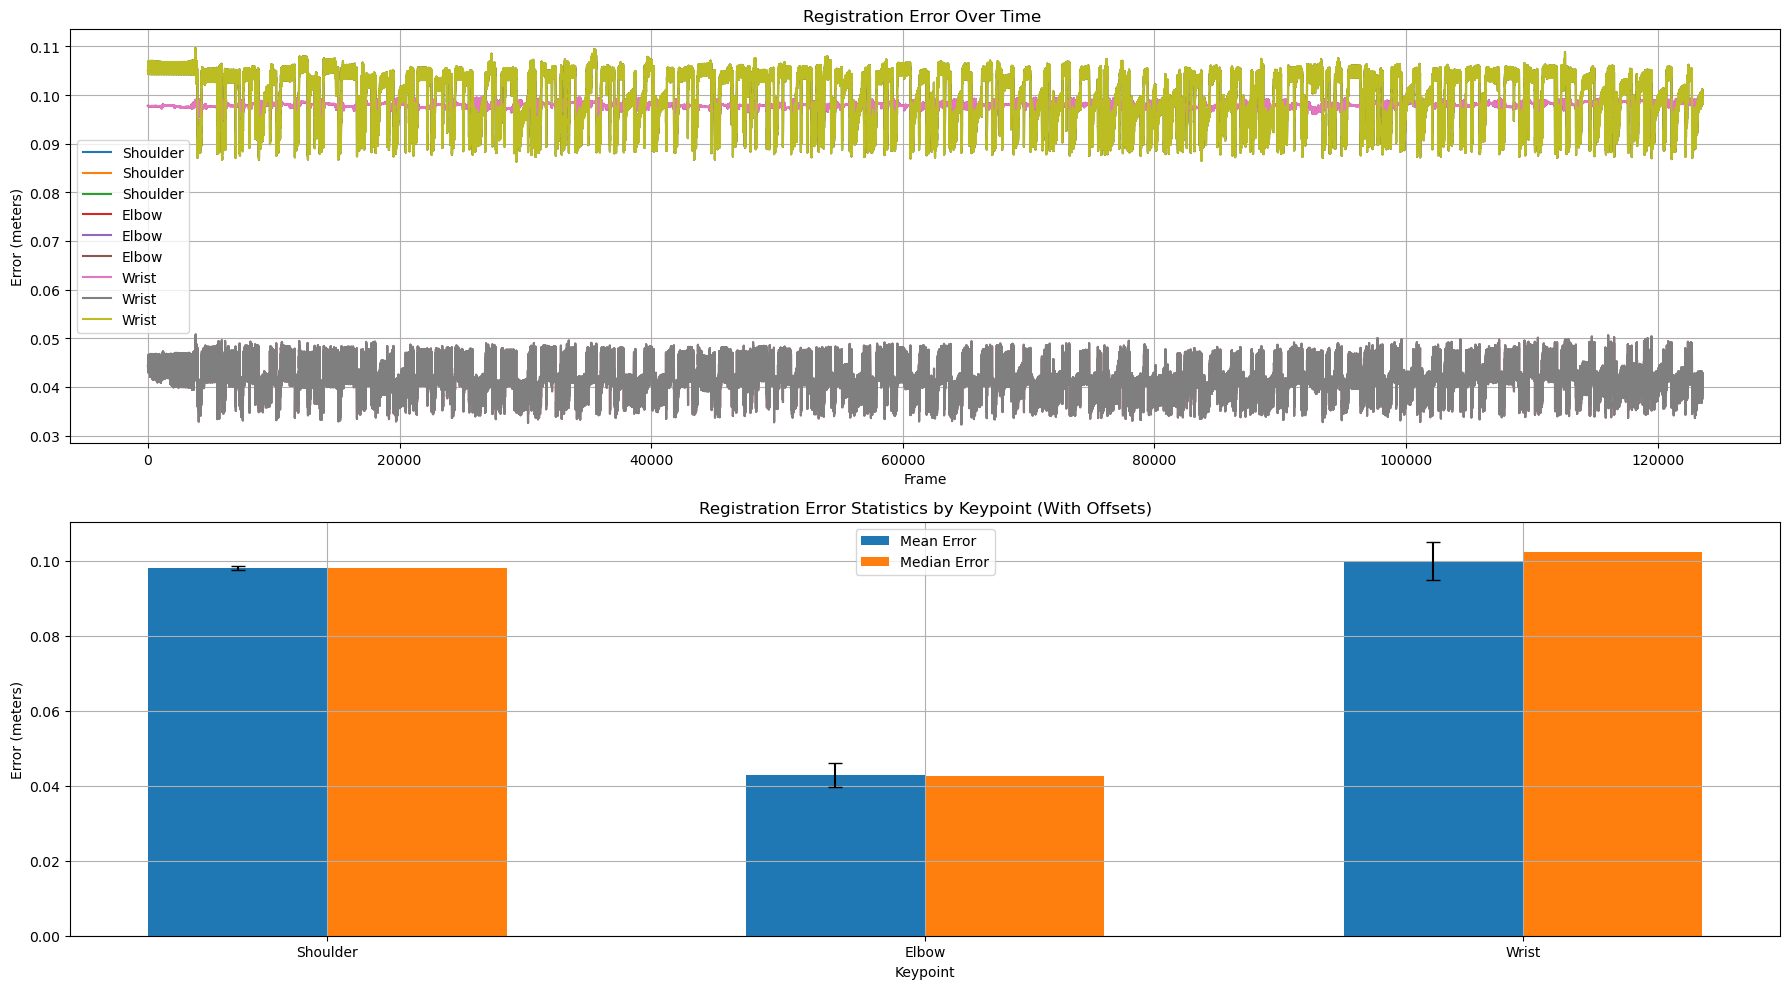


Registration Error Statistics (with offsets applied, in meters):
Shoulder: Mean = 0.09798, Median = 0.09801, Std = 0.00047
Elbow: Mean = 0.04285, Median = 0.04250, Std = 0.00333
Wrist: Mean = 0.09993, Median = 0.10230, Std = 0.00517

Overall Mean Error: 0.08025 meters


In [39]:
# Fixed registration error with proper offset application
import numpy as np
import matplotlib.pyplot as plt

# Load data from the H5 file
with h5py.File(h5_path, 'r') as f:
    kp_data = f['kp_data'][:]  # Original mocap data
    kp_names_bytes = f['kp_names'][:]  # Keypoint names
    xpos = f['xpos'][:]  # STAC model positions
    offsets = f['offsets'][:]  # Key addition: load offsets
    
    # Convert keypoint names from bytes to strings
    kp_names = [name.decode('utf-8') for name in kp_names_bytes]
    if 'names_xpos' in f:
        names_xpos = [name.decode('utf-8') if isinstance(name, bytes) else name 
                      for name in f['names_xpos'][:]]
        print("Model points:", names_xpos)
    
    print(f"Keypoints: {kp_names}")
    print(f"Offsets shape: {offsets.shape}")

# Reshape kp_data for easier comparison (frames, keypoints, xyz)
n_frames = kp_data.shape[0]
kp_data_reshaped = np.zeros((n_frames, 3, 3))
for i in range(3):  # 3 keypoints
    kp_data_reshaped[:, i, 0] = kp_data[:, i*3]     # x coordinate
    kp_data_reshaped[:, i, 1] = kp_data[:, i*3 + 1] # y coordinate
    kp_data_reshaped[:, i, 2] = kp_data[:, i*3 + 2] # z coordinate

keypoint_indices = [3, 6, 8]  # Shoulder, Elbow, Wrist indices in xpos

# Apply offsets to model positions and calculate error
errors = np.zeros((n_frames, len(kp_names)))
for i in range(3):  # 3 keypoints
    model_idx = keypoint_indices[i]
    # Apply the stored offset to the model position
    model_pos_with_offset = xpos[:, model_idx] + offsets[:, i]
    errors[:, i] = np.sqrt(np.sum((kp_data_reshaped[:, i] - model_pos_with_offset) ** 2, axis=1))

# Print example with and without offset for first frame
print("\nFirst frame comparison (with offsets):")
for i, name in enumerate(kp_names):
    model_idx = keypoint_indices[i]
    print(f"{name}:")
    print(f"  Original: {kp_data_reshaped[0, i]}")
    print(f"  Model (raw): {xpos[0, model_idx]}")
    print(f"  Offset: {offsets[0, i]}")
    print(f"  Model (with offset): {xpos[0, model_idx] + offsets[0, i]}")
    print(f"  Distance (with offset): {np.sqrt(np.sum((kp_data_reshaped[0, i] - (xpos[0, model_idx] + offsets[0, i]))**2))}")

# Calculate summary statistics
mean_errors = np.mean(errors, axis=0)
std_errors = np.std(errors, axis=0)
median_errors = np.median(errors, axis=0)

# Create visualization
plt.figure(figsize=(18, 10))

# Plot 1: Error time series (first 1000 frames)
plt.subplot(2, 1, 1)
for i, kp_name in enumerate(kp_names):
    # FIXED: Plot only the relevant column for each keypoint
    plt.plot(range(len(errors)), errors, label=f'{kp_name}')
plt.xlabel('Frame')
plt.ylabel('Error (meters)')
plt.title('Registration Error Over Time ')
plt.legend()
plt.grid(True)

# Plot 2: Error statistics by keypoint
plt.subplot(2, 1, 2)
x = np.arange(len(kp_names))
width = 0.3
plt.bar(x - width/2, mean_errors, width, label='Mean Error')
plt.bar(x + width/2, median_errors, width, label='Median Error')
plt.errorbar(x - width/2, mean_errors, yerr=std_errors, fmt='none', capsize=5, color='black')
plt.xticks(x, kp_names)
plt.xlabel('Keypoint')
plt.ylabel('Error (meters)')
plt.title('Registration Error Statistics by Keypoint (With Offsets)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Print summary statistics
print("\nRegistration Error Statistics (with offsets applied, in meters):")
for i, kp_name in enumerate(kp_names):
    print(f"{kp_name}: Mean = {mean_errors[i]:.5f}, Median = {median_errors[i]:.5f}, Std = {std_errors[i]:.5f}")

print(f"\nOverall Mean Error: {np.mean(mean_errors):.5f} meters")

In [40]:
import h5py
import numpy as np

# Path to the new file
mujoco_h5_path = '/root/vast/eric/stac-mjx/mujoco_aligned_tracking_full.h5'

# Load and display keys
with h5py.File(mujoco_h5_path, 'r') as f:
    keys = list(f.keys())
    print("Available keys:", keys)
    
    # Get shapes of main arrays
    for key in keys:
        try:
            shape = f[key].shape
            print(f"{key}: shape {shape}")
            
            # For the first few items in arrays, show sample values
            if len(shape) > 0 and 'names' not in key.lower():
                sample_size = min(3, shape[0])
                print(f"  Sample values: {f[key][:sample_size]}")
            # For string arrays
            elif 'names' in key.lower():
                sample = [name.decode('utf-8') if isinstance(name, bytes) else name 
                          for name in f[key][:5]]
                print(f"  Sample values: {sample}")
        except:
            print(f"Could not display shape/sample for {key}")
    
    # If this file has keypoints and registration, check differences
    if 'kp_data' in keys and 'xpos' in keys:
        print("\nComparison of first frame keypoints vs model points:")
        kp_data = f['kp_data'][0]
        xpos = f['xpos'][0]
        kp_names = [name.decode('utf-8') for name in f['kp_names'][:]] if 'kp_names' in keys else []
        print(f"First frame error: {np.mean(np.linalg.norm(kp_data.reshape(-1, 3) - xpos[:len(kp_data)//3], axis=1))}")

Available keys: ['tracks']
tracks: shape (123548, 1, 3, 3)
  Sample values: [[[[-0.02253626  0.01186064  0.06803158]
   [-0.02969785  0.00852527  0.06331139]
   [-0.02941695  0.01192201  0.06327321]]]


 [[[-0.02251167  0.01183868  0.06804563]
   [-0.02968961  0.00852807  0.06332453]
   [-0.02941695  0.01192201  0.06327321]]]


 [[[-0.02249794  0.01182515  0.06805287]
   [-0.02968492  0.00853099  0.06332988]
   [-0.02941695  0.01192201  0.06327321]]]]


In [44]:
import h5py
import numpy as np

# Define paths to both H5 files
stac_path = '/root/vast/eric/stac-mjx/mouse_arm_ik_only_new_full_copy.h5'
mujoco_path = '/root/vast/eric/stac-mjx/mujoco_aligned_tracking_full.h5'

# Load and extract data from both files
with h5py.File(stac_path, 'r') as f:
    kp_data = f['kp_data'][:]
    kp_names = [name.decode('utf-8') for name in f['kp_names'][:]]

with h5py.File(mujoco_path, 'r') as f:
    mujoco_tracks = f['tracks'][:]  # Shape: (frames, 1, 3, 3)

# Reshape kp_data from (frames, 9) to (frames, 3, 3)
n_frames = kp_data.shape[0]
kp_data_reshaped = np.zeros((n_frames, 3, 3))
for i in range(3):  # 3 keypoints
    kp_data_reshaped[:, i, 0] = kp_data[:, i*3]     # x coordinate
    kp_data_reshaped[:, i, 1] = kp_data[:, i*3 + 1] # y coordinate
    kp_data_reshaped[:, i, 2] = kp_data[:, i*3 + 2] # z coordinate

# Reshape mujoco tracks from (frames, 1, 3, 3) to (frames, 3, 3)
mujoco_tracks_reshaped = mujoco_tracks[:, 0, :, :]

# Calculate error between original keypoints and MuJoCo aligned tracks
errors = np.zeros((n_frames, 3))  # For each frame, 3 keypoints
for i in range(3):  # 3 keypoints
    errors[:, i] = np.sqrt(np.sum((kp_data_reshaped[:, i] - mujoco_tracks_reshaped[:, i]) ** 2, axis=1))

# Calculate error statistics
mean_errors = np.mean(errors, axis=0)
std_errors = np.std(errors, axis=0)
median_errors = np.median(errors, axis=0)
max_errors = np.max(errors, axis=0)
min_errors = np.min(errors, axis=0)

# Print error statistics
print("Original Keypoints vs MuJoCo Aligned Tracks Error (meters):")
print("-----------------------------------------------------------")
print(f"Overall Mean Error: {np.mean(errors):.6f} meters")
print(f"Overall Median Error: {np.median(errors):.6f} meters")
print(f"Overall Max Error: {np.max(errors):.6f} meters")
print(f"Overall Min Error: {np.min(errors):.6f} meters")
print("\nError statistics by keypoint:")
for i, name in enumerate(kp_names):
    print(f"{name}:")
    print(f"  Mean: {mean_errors[i]:.6f} meters")
    print(f"  Median: {median_errors[i]:.6f} meters")
    print(f"  Std Dev: {std_errors[i]:.6f} meters")
    print(f"  Max: {max_errors[i]:.6f} meters")
    print(f"  Min: {min_errors[i]:.6f} meters")

# Check for any frames with errors above threshold (e.g., 1mm)
high_error_threshold = 0.001  # 1mm
high_error_frames = np.where(np.any(errors > high_error_threshold, axis=1))[0]
if len(high_error_frames) > 0:
    print(f"\nFound {len(high_error_frames)} frames with errors > {high_error_threshold*1000}mm")
    print(f"Sample high error frames: {high_error_frames[:5]} ...")
else:
    print(f"\nNo frames found with errors > {high_error_threshold*1000}mm")

Original Keypoints vs MuJoCo Aligned Tracks Error (meters):
-----------------------------------------------------------
Overall Mean Error: 0.000000 meters
Overall Median Error: 0.000000 meters
Overall Max Error: 0.000000 meters
Overall Min Error: 0.000000 meters

Error statistics by keypoint:
Shoulder:
  Mean: 0.000000 meters
  Median: 0.000000 meters
  Std Dev: 0.000000 meters
  Max: 0.000000 meters
  Min: 0.000000 meters
Elbow:
  Mean: 0.000000 meters
  Median: 0.000000 meters
  Std Dev: 0.000000 meters
  Max: 0.000000 meters
  Min: 0.000000 meters
Wrist:
  Mean: 0.000000 meters
  Median: 0.000000 meters
  Std Dev: 0.000000 meters
  Max: 0.000000 meters
  Min: 0.000000 meters

No frames found with errors > 1.0mm


Found 50 fit files and 49 ik files

Processing fit files...

Processing ik files...

Successfully processed 50 fit files and 49 ik files


/tmp/ipykernel_268636/3797876332.py:160: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(box_data, labels=['Fit Files', 'IK Files'])


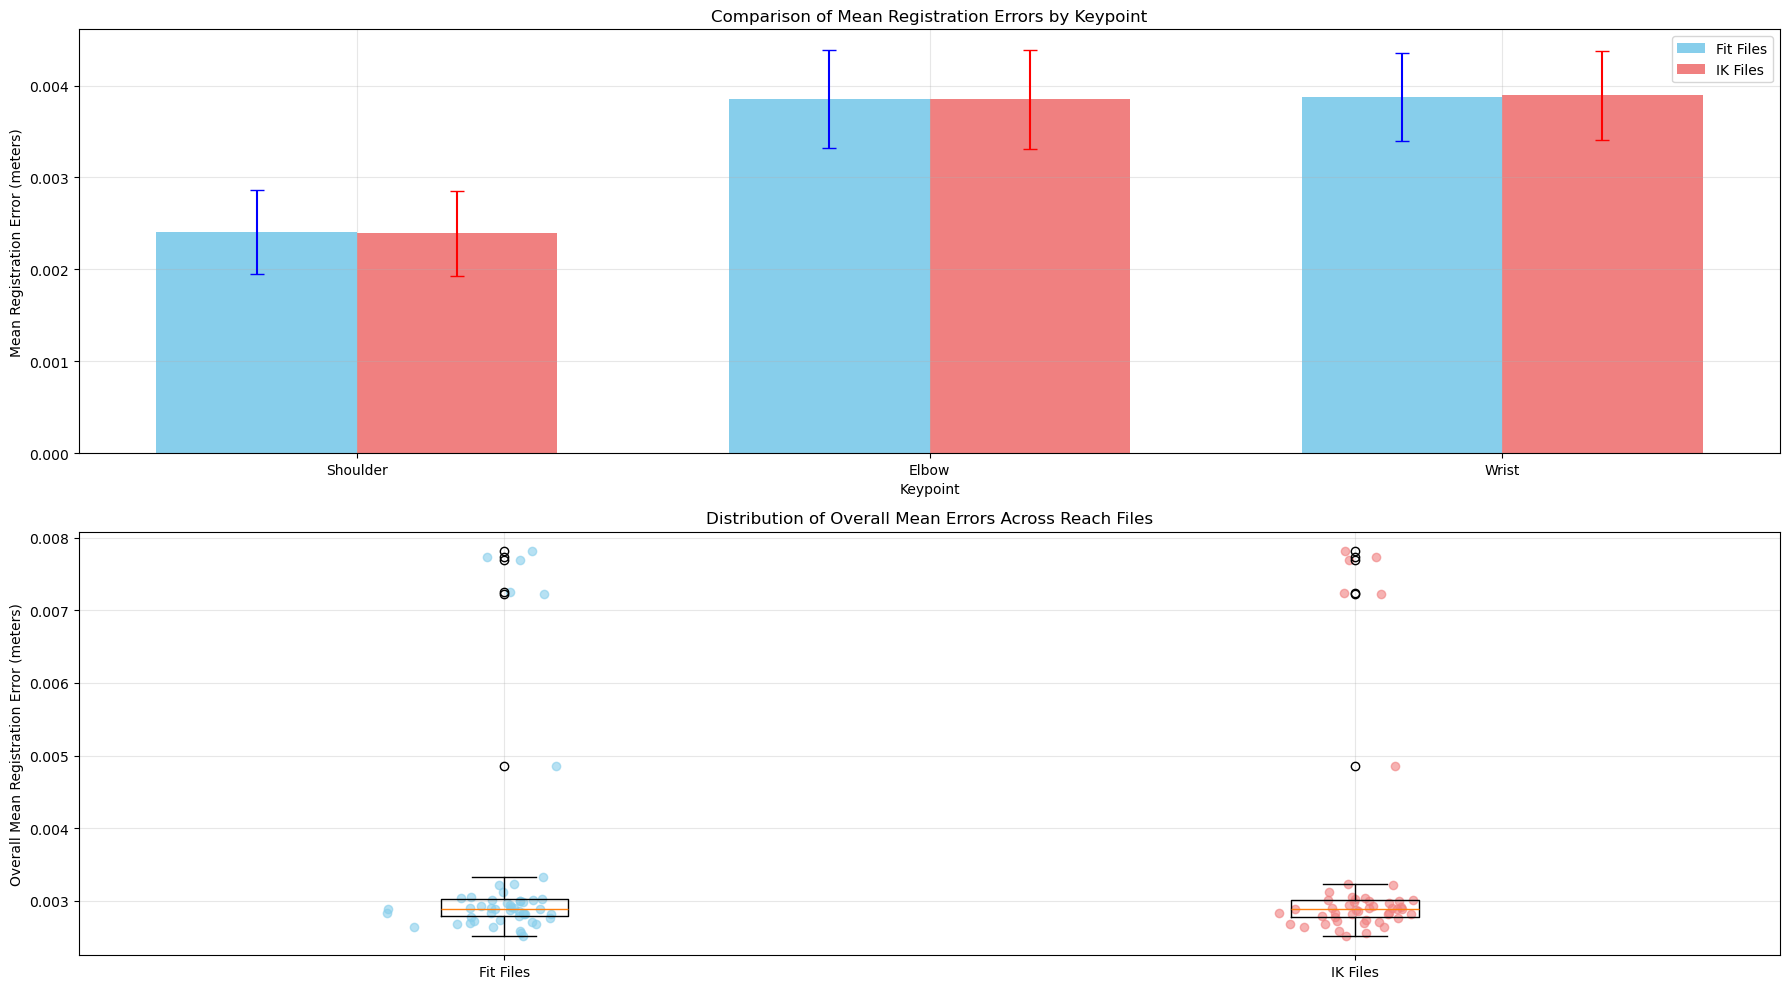


--- Registration Error Summary ---

Fit Files (aggregate of all reaches):
  Shoulder: Mean = 0.00240, Median = 0.00242, Std = 0.00046
  Elbow: Mean = 0.00385, Median = 0.00383, Std = 0.00053
  Wrist: Mean = 0.00387, Median = 0.00385, Std = 0.00048
  Overall Mean: 0.00338 ± 0.00143 meters
  Range: 0.00251 to 0.00782 meters

IK Files (aggregate of all reaches):
  Shoulder: Mean = 0.00239, Median = 0.00240, Std = 0.00046
  Elbow: Mean = 0.00385, Median = 0.00382, Std = 0.00054
  Wrist: Mean = 0.00389, Median = 0.00387, Std = 0.00048
  Overall Mean: 0.00338 ± 0.00144 meters
  Range: 0.00251 to 0.00782 meters

Statistical comparison (t-test): t=-0.002, p=0.99838
No significant difference


In [ ]:
# Process and compare registration error for groups of reach files
import h5py
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

# Set paths to reach for both _fit and _ik files
reach_files_pattern = "/root/vast/eric/stac-mjx/new_STACed_data/reaches_*.h5"
reach_files = glob.glob(reach_files_pattern)

# Separate into fit and ik files
fit_files = [f for f in reach_files if "_fit.h5" in f]
ik_files = [f for f in reach_files if "_ik.h5" in f]

print(f"Found {len(fit_files)} fit files and {len(ik_files)} ik files")

# Define function to process a single file and calculate registration error
def process_file(file_path, keypoint_indices=[3, 6, 8]):
    """
    Process an H5 file and calculate registration error with offsets applied.
    Returns error statistics or None if processing fails.
    """
    try:
        with h5py.File(file_path, 'r') as f:
            # Check if file has necessary data
            required_keys = ['kp_data', 'xpos', 'offsets', 'kp_names']
            if not all(key in f for key in required_keys):
                print(f"Skipping {file_path}: missing required datasets")
                return None
                
            # Load data
            kp_data = f['kp_data'][:]
            kp_names_bytes = f['kp_names'][:]
            xpos = f['xpos'][:]
            offsets = f['offsets'][:]
            
            # Convert keypoint names
            kp_names = [name.decode('utf-8') for name in kp_names_bytes]
            
            # Get number of frames and check if length is sufficient
            n_frames = kp_data.shape[0]
            if n_frames < 10:  # Minimum frames to be considered valid
                print(f"Skipping {file_path}: too few frames ({n_frames})")
                return None
                
            # Reshape keypoint data
            kp_data_reshaped = np.zeros((n_frames, 3, 3))
            for i in range(3):  # 3 keypoints
                kp_data_reshaped[:, i, 0] = kp_data[:, i*3]
                kp_data_reshaped[:, i, 1] = kp_data[:, i*3 + 1]
                kp_data_reshaped[:, i, 2] = kp_data[:, i*3 + 2]
                
            # Calculate errors with offsets applied
            errors = np.zeros((n_frames, len(kp_names)))
            for i in range(3):  # 3 keypoints
                model_idx = keypoint_indices[i]
                model_pos_with_offset = xpos[:, model_idx] + offsets[:, i]
                errors[:, i] = np.sqrt(np.sum((kp_data_reshaped[:, i] - model_pos_with_offset) ** 2, axis=1))
                
            # Calculate statistics
            mean_errors = np.mean(errors, axis=0)
            std_errors = np.std(errors, axis=0)
            median_errors = np.median(errors, axis=0)
            max_errors = np.max(errors, axis=0)
            
            return {
                'file_name': os.path.basename(file_path),
                'n_frames': n_frames,
                'kp_names': kp_names,
                'mean_errors': mean_errors,
                'median_errors': median_errors,
                'std_errors': std_errors,
                'max_errors': max_errors,
                'overall_mean': np.mean(mean_errors),
                'overall_median': np.median(median_errors),
                'errors': errors  # Keep raw errors for detailed analysis
            }
            
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

# Process all files
print("\nProcessing fit files...")
fit_results = [process_file(f) for f in fit_files]
fit_results = [r for r in fit_results if r is not None]  # Remove failed files

print("\nProcessing ik files...")
ik_results = [process_file(f) for f in ik_files]
ik_results = [r for r in ik_results if r is not None]  # Remove failed files

print(f"\nSuccessfully processed {len(fit_results)} fit files and {len(ik_results)} ik files")

# Aggregate results
if fit_results and ik_results:
    # Calculate aggregate statistics
    def aggregate_results(results):
        # Make sure all files have the same keypoint names
        kp_names = results[0]['kp_names']
        
        # Aggregate mean errors by keypoint
        all_means = np.array([r['mean_errors'] for r in results])
        all_medians = np.array([r['median_errors'] for r in results])
        all_stds = np.array([r['std_errors'] for r in results])
        
        # Get overall stats
        aggregate_means = np.mean(all_means, axis=0)
        aggregate_medians = np.mean(all_medians, axis=0)
        aggregate_stds = np.mean(all_stds, axis=0)
        overall_means = np.array([r['overall_mean'] for r in results])
        
        return {
            'kp_names': kp_names,
            'aggregate_means': aggregate_means,
            'aggregate_medians': aggregate_medians,
            'aggregate_stds': aggregate_stds,
            'overall_mean': np.mean(overall_means),
            'overall_std': np.std(overall_means),
            'min_mean': np.min(overall_means),
            'max_mean': np.max(overall_means)
        }
    
    # Aggregate both result sets
    fit_aggregate = aggregate_results(fit_results)
    ik_aggregate = aggregate_results(ik_results)
    
    # Create comparison visualizations
    plt.figure(figsize=(18, 10))
    
    # Plot 1: Compare mean errors by keypoint between fit and ik
    plt.subplot(2, 1, 1)
    x = np.arange(len(fit_aggregate['kp_names']))
    width = 0.35
    
    plt.bar(x - width/2, fit_aggregate['aggregate_means'], width, label='Fit Files', color='skyblue')
    plt.bar(x + width/2, ik_aggregate['aggregate_means'], width, label='IK Files', color='lightcoral')
    
    # Add error bars
    plt.errorbar(x - width/2, fit_aggregate['aggregate_means'], 
                 yerr=fit_aggregate['aggregate_stds'], fmt='none', capsize=5, color='blue')
    plt.errorbar(x + width/2, ik_aggregate['aggregate_means'], 
                 yerr=ik_aggregate['aggregate_stds'], fmt='none', capsize=5, color='red')
    
    plt.xlabel('Keypoint')
    plt.ylabel('Mean Registration Error (meters)')
    plt.title('Comparison of Mean Registration Errors by Keypoint')
    plt.xticks(x, fit_aggregate['kp_names'])
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Plot 2: Box plot of overall mean errors across reaches
    plt.subplot(2, 1, 2)
    
    fit_overall_means = np.array([r['overall_mean'] for r in fit_results])
    ik_overall_means = np.array([r['overall_mean'] for r in ik_results])
    
    box_data = [fit_overall_means, ik_overall_means]
    plt.boxplot(box_data, labels=['Fit Files', 'IK Files'])
    
    # Add individual data points
    x_fit = np.random.normal(1, 0.04, size=len(fit_overall_means))
    x_ik = np.random.normal(2, 0.04, size=len(ik_overall_means))
    plt.scatter(x_fit, fit_overall_means, alpha=0.6, color='skyblue')
    plt.scatter(x_ik, ik_overall_means, alpha=0.6, color='lightcoral')
    
    plt.ylabel('Overall Mean Registration Error (meters)')
    plt.title('Distribution of Overall Mean Errors Across Reach Files')
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Print summary statistics
    print("\n--- Registration Error Summary ---")
    print("\nFit Files (aggregate of all reaches):")
    for i, name in enumerate(fit_aggregate['kp_names']):
        print(f"  {name}: Mean = {fit_aggregate['aggregate_means'][i]:.5f}, "
              f"Median = {fit_aggregate['aggregate_medians'][i]:.5f}, "
              f"Std = {fit_aggregate['aggregate_stds'][i]:.5f}")
    print(f"  Overall Mean: {fit_aggregate['overall_mean']:.5f} ± {fit_aggregate['overall_std']:.5f} meters")
    print(f"  Range: {fit_aggregate['min_mean']:.5f} to {fit_aggregate['max_mean']:.5f} meters")
    
    print("\nIK Files (aggregate of all reaches):")
    for i, name in enumerate(ik_aggregate['kp_names']):
        print(f"  {name}: Mean = {ik_aggregate['aggregate_means'][i]:.5f}, "
              f"Median = {ik_aggregate['aggregate_medians'][i]:.5f}, "
              f"Std = {ik_aggregate['aggregate_stds'][i]:.5f}")
    print(f"  Overall Mean: {ik_aggregate['overall_mean']:.5f} ± {ik_aggregate['overall_std']:.5f} meters")
    print(f"  Range: {ik_aggregate['min_mean']:.5f} to {ik_aggregate['max_mean']:.5f} meters")
    
    # Statistical comparison
    from scipy import stats
    t_stat, p_val = stats.ttest_ind(fit_overall_means, ik_overall_means)
    print(f"\nStatistical comparison (t-test): t={t_stat:.3f}, p={p_val:.5f}")
    print("Significant difference" if p_val < 0.05 else "No significant difference")
    
else:
    print("Insufficient data for comparison.")

Found 50 fit files and 49 ik files

Processing fit files...

Processing ik files...

Successfully processed 50 fit files and 49 ik files


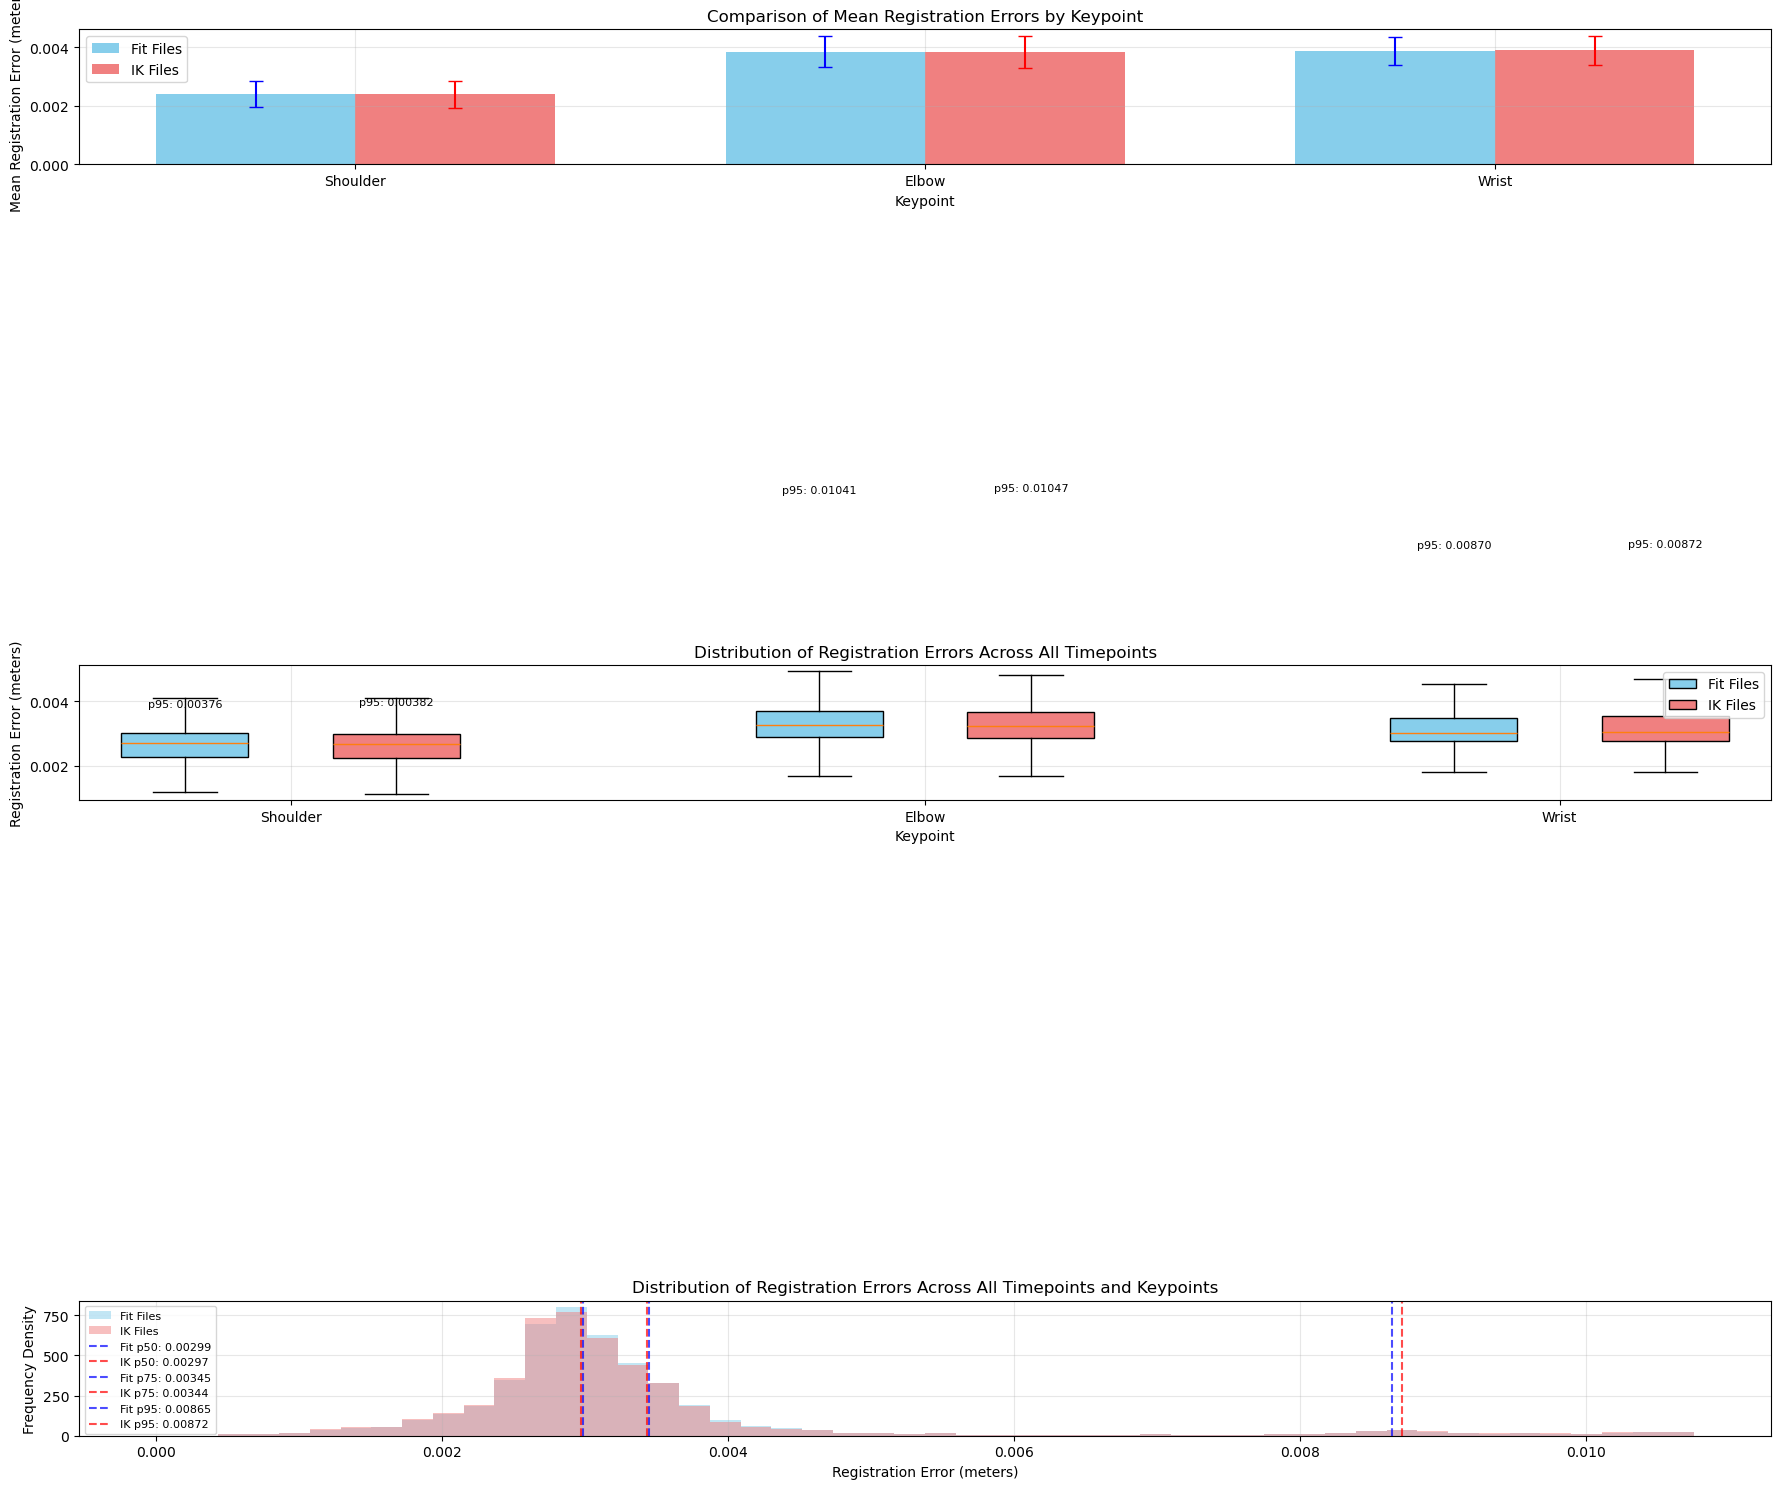


--- Registration Error Summary ---

Fit Files (aggregate of all reaches):
  Shoulder: Mean = 0.00240, Median = 0.00242, Std = 0.00046
  Elbow: Mean = 0.00385, Median = 0.00383, Std = 0.00053
  Wrist: Mean = 0.00387, Median = 0.00385, Std = 0.00048
  Overall Mean: 0.00338 ± 0.00143 meters
  Range: 0.00251 to 0.00782 meters

Full distribution percentiles (all timepoints, all files):
  Shoulder:
    Fit: p50=0.00270, p95=0.00376
    IK: p50=0.00267, p95=0.00382
  Elbow:
    Fit: p50=0.00328, p95=0.01041
    IK: p50=0.00323, p95=0.01047
  Wrist:
    Fit: p50=0.00303, p95=0.00870
    IK: p50=0.00305, p95=0.00872

IK Files (aggregate of all reaches):
  Shoulder: Mean = 0.00239, Median = 0.00240, Std = 0.00046
  Elbow: Mean = 0.00385, Median = 0.00382, Std = 0.00054
  Wrist: Mean = 0.00389, Median = 0.00387, Std = 0.00048
  Overall Mean: 0.00338 ± 0.00144 meters
  Range: 0.00251 to 0.00782 meters

Statistical comparison of all timepoints (t-test): t=-0.368, p=0.71318
No significant differenc

In [ ]:
# Process and compare registration error for groups of reach files
import h5py
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

# Set paths to reach for both _fit and _ik files
reach_files_pattern = "/root/vast/eric/stac-mjx/new_STACed_data/reaches_*.h5"
reach_files = glob.glob(reach_files_pattern)

# Separate into fit and ik files
fit_files = [f for f in reach_files if "_fit.h5" in f]
ik_files = [f for f in reach_files if "_ik.h5" in f]

print(f"Found {len(fit_files)} fit files and {len(ik_files)} ik files")

# Define function to process a single file and calculate registration error
def process_file(file_path, keypoint_indices=[3, 6, 8]):
    """
    Process an H5 file and calculate registration error with offsets applied.
    Returns error statistics or None if processing fails.
    """
    try:
        with h5py.File(file_path, 'r') as f:
            # Check if file has necessary data
            required_keys = ['kp_data', 'xpos', 'offsets', 'kp_names']
            if not all(key in f for key in required_keys):
                print(f"Skipping {file_path}: missing required datasets")
                return None
                
            # Load data
            kp_data = f['kp_data'][:]
            kp_names_bytes = f['kp_names'][:]
            xpos = f['xpos'][:]
            offsets = f['offsets'][:]  # Offsets are loaded here
            
            # Convert keypoint names
            kp_names = [name.decode('utf-8') for name in kp_names_bytes]
            
            # Get number of frames and check if length is sufficient
            n_frames = kp_data.shape[0]
            if n_frames < 10:  # Minimum frames to be considered valid
                print(f"Skipping {file_path}: too few frames ({n_frames})")
                return None
                
            # Reshape keypoint data
            kp_data_reshaped = np.zeros((n_frames, 3, 3))
            for i in range(3):  # 3 keypoints
                kp_data_reshaped[:, i, 0] = kp_data[:, i*3]
                kp_data_reshaped[:, i, 1] = kp_data[:, i*3 + 1]
                kp_data_reshaped[:, i, 2] = kp_data[:, i*3 + 2]
                
            # Calculate errors with offsets applied
            errors = np.zeros((n_frames, len(kp_names)))
            for i in range(3):  # 3 keypoints
                model_idx = keypoint_indices[i]
                # Offsets are applied here to model positions
                model_pos_with_offset = xpos[:, model_idx] + offsets[:, i]
                errors[:, i] = np.sqrt(np.sum((kp_data_reshaped[:, i] - model_pos_with_offset) ** 2, axis=1))
                
            # Calculate statistics
            mean_errors = np.mean(errors, axis=0)
            std_errors = np.std(errors, axis=0)
            median_errors = np.median(errors, axis=0)
            max_errors = np.max(errors, axis=0)
            
            return {
                'file_name': os.path.basename(file_path),
                'n_frames': n_frames,
                'kp_names': kp_names,
                'mean_errors': mean_errors,
                'median_errors': median_errors,
                'std_errors': std_errors,
                'max_errors': max_errors,
                'overall_mean': np.mean(mean_errors),
                'overall_median': np.median(median_errors),
                'errors': errors  # Keep raw errors for detailed analysis
            }
            
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

# Process all files
print("\nProcessing fit files...")
fit_results = [process_file(f) for f in fit_files]
fit_results = [r for r in fit_results if r is not None]  # Remove failed files

print("\nProcessing ik files...")
ik_results = [process_file(f) for f in ik_files]
ik_results = [r for r in ik_results if r is not None]  # Remove failed files

print(f"\nSuccessfully processed {len(fit_results)} fit files and {len(ik_results)} ik files")

# Aggregate results
if fit_results and ik_results:
    # Calculate aggregate statistics
    def aggregate_results(results):
        # Make sure all files have the same keypoint names
        kp_names = results[0]['kp_names']
        
        # Aggregate mean errors by keypoint
        all_means = np.array([r['mean_errors'] for r in results])
        all_medians = np.array([r['median_errors'] for r in results])
        all_stds = np.array([r['std_errors'] for r in results])
        
        # Get overall stats
        aggregate_means = np.mean(all_means, axis=0)
        aggregate_medians = np.mean(all_medians, axis=0)
        aggregate_stds = np.mean(all_stds, axis=0)
        overall_means = np.array([r['overall_mean'] for r in results])
        
        # Concatenate all errors across all timepoints for all files
        all_errors = np.concatenate([r['errors'] for r in results], axis=0)
        
        return {
            'kp_names': kp_names,
            'aggregate_means': aggregate_means,
            'aggregate_medians': aggregate_medians,
            'aggregate_stds': aggregate_stds,
            'overall_mean': np.mean(overall_means),
            'overall_std': np.std(overall_means),
            'min_mean': np.min(overall_means),
            'max_mean': np.max(overall_means),
            'all_errors': all_errors  # All timepoints across all files
        }
    
    # Aggregate both result sets
    fit_aggregate = aggregate_results(fit_results)
    ik_aggregate = aggregate_results(ik_results)
    
    # Create comparison visualizations
    plt.figure(figsize=(18, 15))
    
    # Plot 1: Compare mean errors by keypoint between fit and ik
    plt.subplot(3, 1, 1)
    x = np.arange(len(fit_aggregate['kp_names']))
    width = 0.35
    
    plt.bar(x - width/2, fit_aggregate['aggregate_means'], width, label='Fit Files', color='skyblue')
    plt.bar(x + width/2, ik_aggregate['aggregate_means'], width, label='IK Files', color='lightcoral')
    
    # Add error bars
    plt.errorbar(x - width/2, fit_aggregate['aggregate_means'], 
                 yerr=fit_aggregate['aggregate_stds'], fmt='none', capsize=5, color='blue')
    plt.errorbar(x + width/2, ik_aggregate['aggregate_means'], 
                 yerr=ik_aggregate['aggregate_stds'], fmt='none', capsize=5, color='red')
    
    plt.xlabel('Keypoint')
    plt.ylabel('Mean Registration Error (meters)')
    plt.title('Comparison of Mean Registration Errors by Keypoint')
    plt.xticks(x, fit_aggregate['kp_names'])
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Plot 2: Distribution of errors across all timepoints for each keypoint
    plt.subplot(3, 1, 2)
    
    # Collect data for boxplot - errors for all timepoints, grouped by keypoint
    kp_names = fit_aggregate['kp_names']
    n_kps = len(kp_names)
    
    # Create box data arrays
    fit_boxdata = [fit_aggregate['all_errors'][:, i] for i in range(n_kps)]
    ik_boxdata = [ik_aggregate['all_errors'][:, i] for i in range(n_kps)]
    
    # Set positions for box plots
    positions = np.arange(1, n_kps*3, 3)
    
    # Create boxplots - now with showfliers=False to hide outliers
    bp_fit = plt.boxplot(fit_boxdata, positions=positions-0.5, widths=0.6,
                         patch_artist=True, showfliers=False)
    bp_ik = plt.boxplot(ik_boxdata, positions=positions+0.5, widths=0.6, 
                         patch_artist=True, showfliers=False)
    
    # Set colors
    for box in bp_fit['boxes']:
        box.set(facecolor='skyblue')
    for box in bp_ik['boxes']:
        box.set(facecolor='lightcoral')
    
    # Annotate percentiles
    for i in range(n_kps):
        fit_p95 = np.percentile(fit_boxdata[i], 95)
        ik_p95 = np.percentile(ik_boxdata[i], 95)
        plt.text(positions[i]-0.5, fit_p95, f"p95: {fit_p95:.5f}", 
                 ha='center', va='bottom', fontsize=8)
        plt.text(positions[i]+0.5, ik_p95, f"p95: {ik_p95:.5f}", 
                 ha='center', va='bottom', fontsize=8)
    
    # Set labels and title
    plt.xlabel('Keypoint')
    plt.ylabel('Registration Error (meters)')
    plt.title('Distribution of Registration Errors Across All Timepoints')
    plt.xticks(positions, kp_names)
    plt.legend([bp_fit["boxes"][0], bp_ik["boxes"][0]], 
               ['Fit Files', 'IK Files'], loc='upper right')
    plt.grid(True, alpha=0.3)
    
    # Plot 3: Histogram of errors across all timepoints and keypoints
    plt.subplot(3, 1, 3)
    
    # Flatten all errors for histogram
    fit_all_flat = fit_aggregate['all_errors'].flatten()
    ik_all_flat = ik_aggregate['all_errors'].flatten()
    
    # Set histogram parameters
    bins = 50
    max_val = max(np.percentile(fit_all_flat, 99), np.percentile(ik_all_flat, 99))
    
    # Create histograms
    plt.hist(fit_all_flat, bins=bins, alpha=0.5, color='skyblue', 
             range=(0, max_val), density=True, label='Fit Files')
    plt.hist(ik_all_flat, bins=bins, alpha=0.5, color='lightcoral', 
             range=(0, max_val), density=True, label='IK Files')
    
    # Add percentile lines
    for perc in [50, 75, 95]:
        fit_perc = np.percentile(fit_all_flat, perc)
        ik_perc = np.percentile(ik_all_flat, perc)
        plt.axvline(fit_perc, color='blue', linestyle='--', alpha=0.7,
                    label=f'Fit p{perc}: {fit_perc:.5f}')
        plt.axvline(ik_perc, color='red', linestyle='--', alpha=0.7,
                    label=f'IK p{perc}: {ik_perc:.5f}')
    
    plt.xlabel('Registration Error (meters)')
    plt.ylabel('Frequency Density')
    plt.title('Distribution of Registration Errors Across All Timepoints and Keypoints')
    plt.legend(fontsize=8)
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Print summary statistics
    print("\n--- Registration Error Summary ---")
    print("\nFit Files (aggregate of all reaches):")
    for i, name in enumerate(fit_aggregate['kp_names']):
        print(f"  {name}: Mean = {fit_aggregate['aggregate_means'][i]:.5f}, "
              f"Median = {fit_aggregate['aggregate_medians'][i]:.5f}, "
              f"Std = {fit_aggregate['aggregate_stds'][i]:.5f}")
    print(f"  Overall Mean: {fit_aggregate['overall_mean']:.5f} ± {fit_aggregate['overall_std']:.5f} meters")
    print(f"  Range: {fit_aggregate['min_mean']:.5f} to {fit_aggregate['max_mean']:.5f} meters")
    
    # Additional percentile statistics for full distribution
    print("\nFull distribution percentiles (all timepoints, all files):")
    for i, name in enumerate(fit_aggregate['kp_names']):
        fit_data = fit_aggregate['all_errors'][:, i]
        ik_data = ik_aggregate['all_errors'][:, i]
        
        print(f"  {name}:")
        print(f"    Fit: p50={np.percentile(fit_data, 50):.5f}, p95={np.percentile(fit_data, 95):.5f}")
        print(f"    IK: p50={np.percentile(ik_data, 50):.5f}, p95={np.percentile(ik_data, 95):.5f}")
    
    print("\nIK Files (aggregate of all reaches):")
    for i, name in enumerate(ik_aggregate['kp_names']):
        print(f"  {name}: Mean = {ik_aggregate['aggregate_means'][i]:.5f}, "
              f"Median = {ik_aggregate['aggregate_medians'][i]:.5f}, "
              f"Std = {ik_aggregate['aggregate_stds'][i]:.5f}")
    print(f"  Overall Mean: {ik_aggregate['overall_mean']:.5f} ± {ik_aggregate['overall_std']:.5f} meters")
    print(f"  Range: {ik_aggregate['min_mean']:.5f} to {ik_aggregate['max_mean']:.5f} meters")
    
    # Statistical comparison
    from scipy import stats
    t_stat, p_val = stats.ttest_ind(fit_all_flat, ik_all_flat)
    print(f"\nStatistical comparison of all timepoints (t-test): t={t_stat:.3f}, p={p_val:.5f}")
    print("Significant difference" if p_val < 0.05 else "No significant difference")
    
else:
    print("Insufficient data for comparison.")

Found 50 fit files and 49 ik files

Processing fit files...

Processing ik files...

Successfully processed 50 fit files and 49 ik files


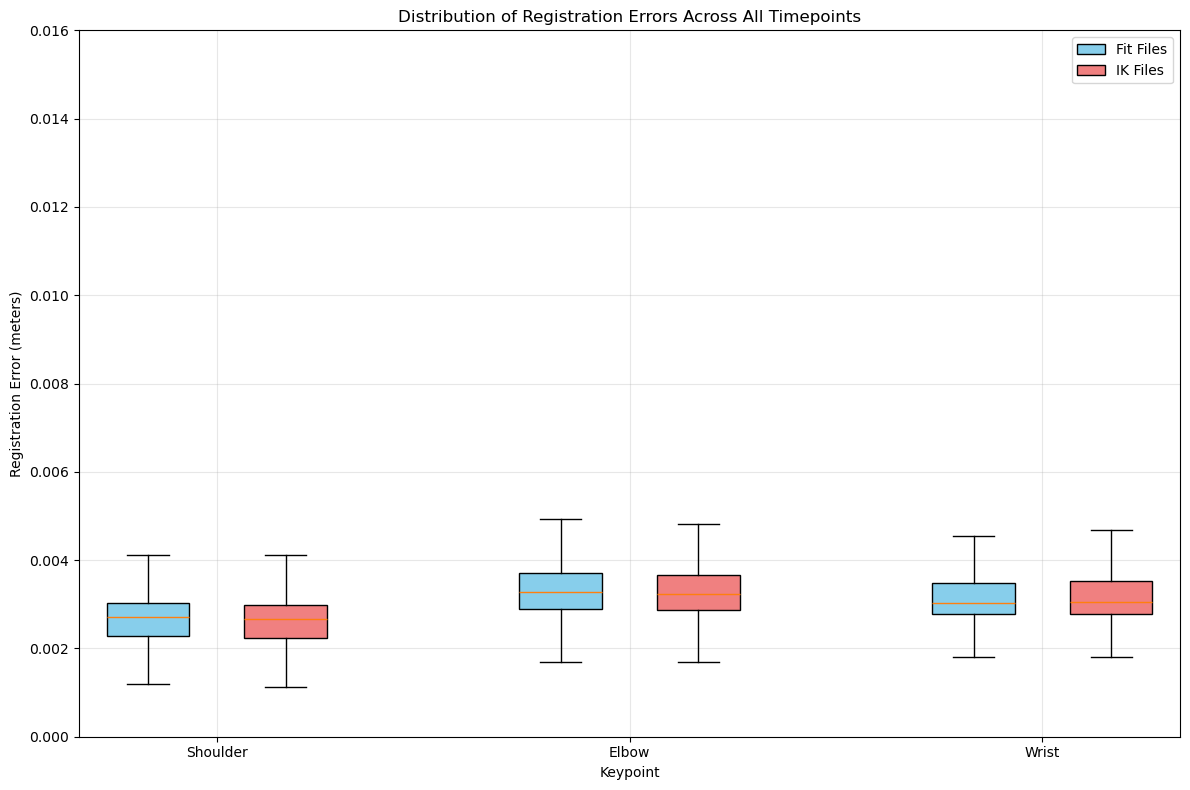


Full distribution percentiles (all timepoints, all files):
  Shoulder:
    Fit: p50=0.00270, p95=0.00376
    IK: p50=0.00267, p95=0.00382
  Elbow:
    Fit: p50=0.00328, p95=0.01041
    IK: p50=0.00323, p95=0.01047
  Wrist:
    Fit: p50=0.00303, p95=0.00870
    IK: p50=0.00305, p95=0.00872

Statistical comparison of all timepoints (t-test): t=-0.368, p=0.71318
No significant difference


In [49]:
# Process and compare registration error for groups of reach files
import h5py
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

# Set paths to reach for both _fit and _ik files
reach_files_pattern = "/root/vast/eric/stac-mjx/reaches_*.h5"
reach_files = glob.glob(reach_files_pattern)

# Separate into fit and ik files
fit_files = [f for f in reach_files if "_fit.h5" in f]
ik_files = [f for f in reach_files if "_ik.h5" in f]

print(f"Found {len(fit_files)} fit files and {len(ik_files)} ik files")

# Define function to process a single file and calculate registration error
def process_file(file_path, keypoint_indices=[3, 6, 8]):
    """
    Process an H5 file and calculate registration error with offsets applied.
    Returns error statistics or None if processing fails.
    """
    try:
        with h5py.File(file_path, 'r') as f:
            # Check if file has necessary data
            required_keys = ['kp_data', 'xpos', 'offsets', 'kp_names']
            if not all(key in f for key in required_keys):
                print(f"Skipping {file_path}: missing required datasets")
                return None
                
            # Load data
            kp_data = f['kp_data'][:]
            kp_names_bytes = f['kp_names'][:]
            xpos = f['xpos'][:]
            offsets = f['offsets'][:]  # Offsets are loaded here
            
            # Convert keypoint names
            kp_names = [name.decode('utf-8') for name in kp_names_bytes]
            
            # Get number of frames and check if length is sufficient
            n_frames = kp_data.shape[0]
            if n_frames < 10:  # Minimum frames to be considered valid
                print(f"Skipping {file_path}: too few frames ({n_frames})")
                return None
                
            # Reshape keypoint data
            kp_data_reshaped = np.zeros((n_frames, 3, 3))
            for i in range(3):  # 3 keypoints
                kp_data_reshaped[:, i, 0] = kp_data[:, i*3]
                kp_data_reshaped[:, i, 1] = kp_data[:, i*3 + 1]
                kp_data_reshaped[:, i, 2] = kp_data[:, i*3 + 2]
                
            # Calculate errors with offsets applied
            errors = np.zeros((n_frames, len(kp_names)))
            for i in range(3):  # 3 keypoints
                model_idx = keypoint_indices[i]
                # Offsets are applied here to model positions
                model_pos_with_offset = xpos[:, model_idx] + offsets[:, i]
                errors[:, i] = np.sqrt(np.sum((kp_data_reshaped[:, i] - model_pos_with_offset) ** 2, axis=1))
                
            # Calculate statistics
            mean_errors = np.mean(errors, axis=0)
            std_errors = np.std(errors, axis=0)
            median_errors = np.median(errors, axis=0)
            max_errors = np.max(errors, axis=0)
            
            return {
                'file_name': os.path.basename(file_path),
                'n_frames': n_frames,
                'kp_names': kp_names,
                'mean_errors': mean_errors,
                'median_errors': median_errors,
                'std_errors': std_errors,
                'max_errors': max_errors,
                'overall_mean': np.mean(mean_errors),
                'overall_median': np.median(median_errors),
                'errors': errors  # Keep raw errors for detailed analysis
            }
            
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

# Process all files
print("\nProcessing fit files...")
fit_results = [process_file(f) for f in fit_files]
fit_results = [r for r in fit_results if r is not None]  # Remove failed files

print("\nProcessing ik files...")
ik_results = [process_file(f) for f in ik_files]
ik_results = [r for r in ik_results if r is not None]  # Remove failed files

print(f"\nSuccessfully processed {len(fit_results)} fit files and {len(ik_results)} ik files")

# Aggregate results
if fit_results and ik_results:
    # Calculate aggregate statistics
    def aggregate_results(results):
        # Make sure all files have the same keypoint names
        kp_names = results[0]['kp_names']
        
        # Aggregate mean errors by keypoint
        all_means = np.array([r['mean_errors'] for r in results])
        all_medians = np.array([r['median_errors'] for r in results])
        all_stds = np.array([r['std_errors'] for r in results])
        
        # Get overall stats
        aggregate_means = np.mean(all_means, axis=0)
        aggregate_medians = np.mean(all_medians, axis=0)
        aggregate_stds = np.mean(all_stds, axis=0)
        overall_means = np.array([r['overall_mean'] for r in results])
        
        # Concatenate all errors across all timepoints for all files
        all_errors = np.concatenate([r['errors'] for r in results], axis=0)
        
        return {
            'kp_names': kp_names,
            'aggregate_means': aggregate_means,
            'aggregate_medians': aggregate_medians,
            'aggregate_stds': aggregate_stds,
            'overall_mean': np.mean(overall_means),
            'overall_std': np.std(overall_means),
            'min_mean': np.min(overall_means),
            'max_mean': np.max(overall_means),
            'all_errors': all_errors  # All timepoints across all files
        }
    
    # Aggregate both result sets
    fit_aggregate = aggregate_results(fit_results)
    ik_aggregate = aggregate_results(ik_results)
    
    # Create visualization - Only the boxplot
    plt.figure(figsize=(12, 8))
    
    # Distribution of errors across all timepoints for each keypoint
    kp_names = fit_aggregate['kp_names']
    n_kps = len(kp_names)
    
    # Create box data arrays
    fit_boxdata = [fit_aggregate['all_errors'][:, i] for i in range(n_kps)]
    ik_boxdata = [ik_aggregate['all_errors'][:, i] for i in range(n_kps)]
    
    # Set positions for box plots
    positions = np.arange(1, n_kps*3, 3)
    
    # Create boxplots - with showfliers=False to hide outliers
    bp_fit = plt.boxplot(fit_boxdata, positions=positions-0.5, widths=0.6,
                        patch_artist=True, showfliers=False)
    bp_ik = plt.boxplot(ik_boxdata, positions=positions+0.5, widths=0.6, 
                        patch_artist=True, showfliers=False)
    
    # Set colors
    for box in bp_fit['boxes']:
        box.set(facecolor='skyblue')
    for box in bp_ik['boxes']:
        box.set(facecolor='lightcoral')
    
    # Annotate percentiles
    # for i in range(n_kps):
    #     fit_p95 = np.percentile(fit_boxdata[i], 95)
    #     ik_p95 = np.percentile(ik_boxdata[i], 95)
    #     plt.text(positions[i]-0.5, fit_p95, f"p95: {fit_p95:.5f}", 
    #             ha='center', va='bottom', fontsize=8)
    #     plt.text(positions[i]+0.5, ik_p95, f"p95: {ik_p95:.5f}", 
    #             ha='center', va='bottom', fontsize=8)
    
    # Set labels and title
    plt.xlabel('Keypoint')
    plt.ylabel('Registration Error (meters)')
    plt.title('Distribution of Registration Errors Across All Timepoints')
    plt.xticks(positions, kp_names)
    plt.legend([bp_fit["boxes"][0], bp_ik["boxes"][0]], 
              ['Fit Files', 'IK Files'], loc='upper right')
    plt.grid(True, alpha=0.3)
    
    # Set y-axis from 0 to 16mm (0.016 meters)
    plt.ylim(0, 0.016)
    
    plt.tight_layout()
    plt.show()
    
    # Print summary statistics for the full distribution
    print("\nFull distribution percentiles (all timepoints, all files):")
    for i, name in enumerate(fit_aggregate['kp_names']):
        fit_data = fit_aggregate['all_errors'][:, i]
        ik_data = ik_aggregate['all_errors'][:, i]
        
        print(f"  {name}:")
        print(f"    Fit: p50={np.percentile(fit_data, 50):.5f}, p95={np.percentile(fit_data, 95):.5f}")
        print(f"    IK: p50={np.percentile(ik_data, 50):.5f}, p95={np.percentile(ik_data, 95):.5f}")
    
    # Statistical comparison
    from scipy import stats
    fit_all_flat = fit_aggregate['all_errors'].flatten()
    ik_all_flat = ik_aggregate['all_errors'].flatten()
    t_stat, p_val = stats.ttest_ind(fit_all_flat, ik_all_flat)
    print(f"\nStatistical comparison of all timepoints (t-test): t={t_stat:.3f}, p={p_val:.5f}")
    print("Significant difference" if p_val < 0.05 else "No significant difference")
    
else:
    print("Insufficient data for comparison.")

Found 49 ik files


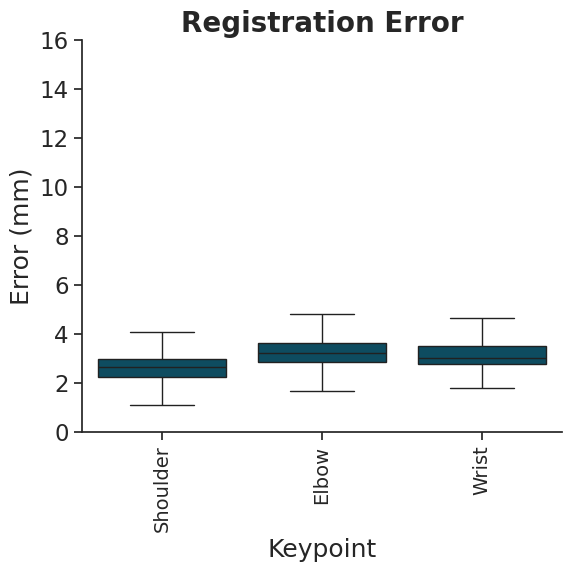

Overall Mean Error: 3.43 mm


In [62]:
# Simplified registration error analysis for IK files with PDF export
import h5py
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from collections import defaultdict

# Set seaborn style and increase font sizes
sns.set(style="ticks", font_scale=1.5)
plt.rcParams.update({'font.size': 16})

# Get only IK files
reach_files_pattern = "/root/vast/eric/stac-mjx/reaches_*.h5"
ik_files = [f for f in glob.glob(reach_files_pattern) if "_ik.h5" in f]
print(f"Found {len(ik_files)} ik files")

# Define function to process a single file and calculate registration error
def process_file(file_path, keypoint_indices=[3, 6, 8]):
    try:
        with h5py.File(file_path, 'r') as f:
            # Load data
            kp_data = f['kp_data'][:]
            kp_names = [name.decode('utf-8') for name in f['kp_names'][:]]
            xpos = f['xpos'][:]
            offsets = f['offsets'][:]
            
            # Reshape keypoint data
            n_frames = kp_data.shape[0]
            kp_data_reshaped = np.zeros((n_frames, 3, 3))
            for i in range(3):  # 3 keypoints
                kp_data_reshaped[:, i, 0] = kp_data[:, i*3]
                kp_data_reshaped[:, i, 1] = kp_data[:, i*3 + 1]
                kp_data_reshaped[:, i, 2] = kp_data[:, i*3 + 2]
                
            # Calculate errors with offsets applied
            errors = np.zeros((n_frames, len(kp_names)))
            for i in range(3):
                model_idx = keypoint_indices[i]
                model_pos_with_offset = xpos[:, model_idx] + offsets[:, i]
                errors[:, i] = np.sqrt(np.sum((kp_data_reshaped[:, i] - model_pos_with_offset) ** 2, axis=1))
                
            return {'kp_names': kp_names, 'errors': errors}
            
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

# Process IK files and aggregate results
ik_results = [process_file(f) for f in ik_files]
ik_results = [r for r in ik_results if r is not None]

if ik_results:
    # Concatenate all errors across all timepoints for all files
    kp_names = ik_results[0]['kp_names']
    all_errors = np.concatenate([r['errors'] for r in ik_results], axis=0)
    
    # Convert from meters to millimeters and prepare data for plotting
    data = []
    for i, kp in enumerate(kp_names):
        for val in all_errors[:, i] * 1000:  # Convert to mm
            data.append({'Keypoint': kp, 'Registration Error (mm)': val})
    df = pd.DataFrame(data)
    
    # Create figure with small size (quarter of original)
    fig, ax = plt.subplots(figsize=(6, 6))
    
    # Plot using seaborn
    sns.boxplot(x='Keypoint', y='Registration Error (mm)', 
                data=df, 
                color='#00536E', 
                showfliers=False,
                ax=ax)
    
    # Remove top and right spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Turn off grid
    ax.grid(False)
    
    # Set vertical orientation for x-tick labels
    plt.xticks(rotation=90, fontsize=14)
    
    # Set larger labels and title
    #ax.set_xlabel('Keypoint', fontsize=18)
    ax.set_ylabel('Error (mm)', fontsize=18)
    ax.set_title('Registration Error', fontsize=20, fontweight='bold')
    
    # Set y-axis from 0 to 16mm
    ax.set_ylim(0, 16)
    
    plt.tight_layout()
    
    # Save to PDF
    plt.savefig('registration_error.pdf', format='pdf', bbox_inches='tight')
    plt.show()
    
    # Print summary statistics
    overall_mean = np.mean(all_errors) * 1000  # Convert to mm
    print(f"Overall Mean Error: {overall_mean:.2f} mm")
    
else:
    print("Insufficient data for analysis.")

Found 49 ik files


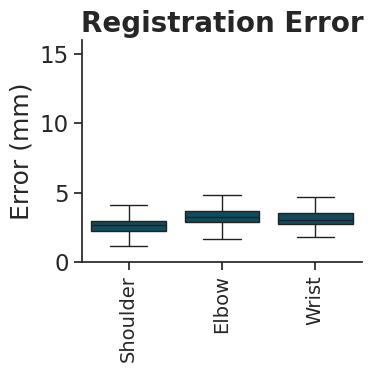

Overall Mean Error: 3.43 mm


In [9]:
# Simplified registration error analysis for IK files with PDF export
import h5py
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from collections import defaultdict

# Set seaborn style and increase font sizes
sns.set(style="ticks", font_scale=1.5)
plt.rcParams.update({'font.size': 16})

# Get only IK files
reach_files_pattern = "/root/vast/eric/stac-mjx/reaches_*.h5"
ik_files = [f for f in glob.glob(reach_files_pattern) if "_ik.h5" in f]
print(f"Found {len(ik_files)} ik files")

# Define function to process a single file and calculate registration error
def process_file(file_path, keypoint_indices=[3, 6, 8]):
    try:
        with h5py.File(file_path, 'r') as f:
            # Load data
            kp_data = f['kp_data'][:]
            kp_names = [name.decode('utf-8') for name in f['kp_names'][:]]
            xpos = f['xpos'][:]
            offsets = f['offsets'][:]
            
            # Reshape keypoint data
            n_frames = kp_data.shape[0]
            kp_data_reshaped = np.zeros((n_frames, 3, 3))
            for i in range(3):  # 3 keypoints
                kp_data_reshaped[:, i, 0] = kp_data[:, i*3]
                kp_data_reshaped[:, i, 1] = kp_data[:, i*3 + 1]
                kp_data_reshaped[:, i, 2] = kp_data[:, i*3 + 2]
                
            # Calculate errors with offsets applied
            errors = np.zeros((n_frames, len(kp_names)))
            for i in range(3):
                model_idx = keypoint_indices[i]
                model_pos_with_offset = xpos[:, model_idx] + offsets[:, i]
                errors[:, i] = np.sqrt(np.sum((kp_data_reshaped[:, i] - model_pos_with_offset) ** 2, axis=1))
                
            return {'kp_names': kp_names, 'errors': errors}
            
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

# Process IK files and aggregate results
ik_results = [process_file(f) for f in ik_files]
ik_results = [r for r in ik_results if r is not None]

if ik_results:
    # Concatenate all errors across all timepoints for all files
    kp_names = ik_results[0]['kp_names']
    all_errors = np.concatenate([r['errors'] for r in ik_results], axis=0)
    
    # Convert from meters to millimeters and prepare data for plotting
    data = []
    for i, kp in enumerate(kp_names):
        for val in all_errors[:, i] * 1000:  # Convert to mm
            data.append({'Keypoint': kp, 'Registration Error (mm)': val})
    df = pd.DataFrame(data)
    
    # Create figure with small size (quarter of original)
    fig, ax = plt.subplots(figsize=(4, 4))
    
    # Plot using seaborn
    sns.boxplot(x='Keypoint', y='Registration Error (mm)', 
                data=df, 
                color='#00536E', 
                showfliers=False,
                ax=ax)
    
    # Remove top and right spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Turn off grid
    ax.grid(False)
    
    # Set vertical orientation for x-tick labels
    plt.xticks(rotation=90, fontsize=14)
    
    # Set larger labels and title
    ax.set_xlabel('')  # Explicitly set to empty string to remove x-label
    ax.set_ylabel('Error (mm)', fontsize=18)
    ax.set_title('Registration Error', fontsize=20, fontweight='bold')
    
    # Set y-axis from 0 to 16mm
    ax.set_ylim(0, 16)
    
    plt.tight_layout()
    
    # Save to PDF
    plt.savefig('registration_error.pdf', format='pdf', bbox_inches='tight')
    plt.show()
    
    # Print summary statistics
    overall_mean = np.mean(all_errors) * 1000  # Convert to mm
    print(f"Overall Mean Error: {overall_mean:.2f} mm")
    
else:
    print("Insufficient data for analysis.")

Found 46 ik files


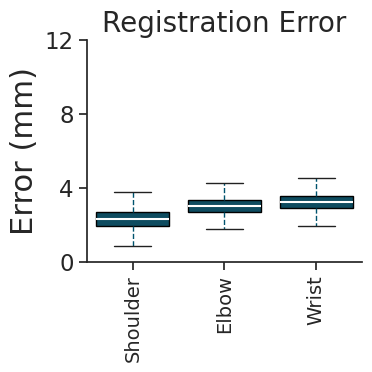

Overall Mean Error: 2.90 mm


In [1]:
# Simplified registration error analysis for IK files with SVG export
import h5py
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import pandas as pd
from collections import defaultdict

# Configure matplotlib to preserve exact colors
# This ensures exact RGB color values are preserved in the SVG output
mpl.rcParams['svg.fonttype'] = 'none'  # Don't convert fonts to paths
mpl.rcParams['svg.hashsalt'] = None  # Preserve identical colors

# Set seaborn style and increase font sizes
sns.set(style="ticks", font_scale=1.5)
plt.rcParams.update({'font.size': 16})

# Get only IK files
reach_files_pattern = "/root/vast/eric/stac-mjx/refined_STACed_data/*.h5"
ik_files = [f for f in glob.glob(reach_files_pattern) if "_ik.h5" in f]
print(f"Found {len(ik_files)} ik files")

# Define function to process a single file and calculate registration error
def process_file(file_path, keypoint_indices=[3, 6, 8]):
    try:
        with h5py.File(file_path, 'r') as f:
            # Load data
            kp_data = f['kp_data'][:]
            kp_names = [name.decode('utf-8') for name in f['kp_names'][:]]
            xpos = f['xpos'][:]
            offsets = f['offsets'][:]
            
            # Reshape keypoint data
            n_frames = kp_data.shape[0]
            kp_data_reshaped = np.zeros((n_frames, 3, 3))
            for i in range(3):  # 3 keypoints
                kp_data_reshaped[:, i, 0] = kp_data[:, i*3]
                kp_data_reshaped[:, i, 1] = kp_data[:, i*3 + 1]
                kp_data_reshaped[:, i, 2] = kp_data[:, i*3 + 2]
                
            # Calculate errors with offsets applied
            errors = np.zeros((n_frames, len(kp_names)))
            for i in range(3):
                model_idx = keypoint_indices[i]
                model_pos_with_offset = xpos[:, model_idx] + offsets[:, i]
                errors[:, i] = np.sqrt(np.sum((kp_data_reshaped[:, i] - model_pos_with_offset) ** 2, axis=1))
                
            return {'kp_names': kp_names, 'errors': errors}
            
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

# Process IK files and aggregate results
ik_results = [process_file(f) for f in ik_files]
ik_results = [r for r in ik_results if r is not None]

if ik_results:
    # Concatenate all errors across all timepoints for all files
    kp_names = ik_results[0]['kp_names']
    all_errors = np.concatenate([r['errors'] for r in ik_results], axis=0)
    
    # Convert from meters to millimeters and prepare data for plotting
    data = []
    for i, kp in enumerate(kp_names):
        for val in all_errors[:, i] * 1000:  # Convert to mm
            data.append({'Keypoint': kp, 'Registration Error (mm)': val})
    df = pd.DataFrame(data)
    
    # Create figure with small size
    fig, ax = plt.subplots(figsize=(4, 4))
    
    # Use a color object with strictly RGB values to avoid color space conversion
    box_color = (0/255, 83/255, 110/255)  # Exact RGB values for #00536E
    
    # Plot using seaborn with explicit median line color and black box outline
    boxplot = sns.boxplot(x='Keypoint', y='Registration Error (mm)', 
                data=df, 
                color=box_color,  # Use RGB tuple instead of hex
                showfliers=False,
                medianprops={"color": "white", "linewidth": 1.5},
                whiskerprops={"linestyle": "--", "color": box_color},
                boxprops={"edgecolor": "black"},  # Add black outline for boxes
                ax=ax)
    
    # Remove top and right spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Turn off grid
    ax.grid(False)
    
    # Set vertical orientation for x-tick labels
    plt.xticks(rotation=90, fontsize=14)
    
    # Set larger labels and title
    ax.set_xlabel('')  # Explicitly set to empty string to remove x-label
    ax.set_ylabel('Error (mm)', fontsize=22)  # Increased font size for y-axis label
    ax.set_title('Registration Error', fontsize=20)
    
    # Set y-axis from 0 to 12mm with ticks every 4mm
    ax.set_ylim(0, 12)
    ax.set_yticks([0, 4, 8, 12])
    
    plt.tight_layout()
    
    # Save to SVG with explicit color handling
    plt.savefig('registration_error.svg', format='svg', bbox_inches='tight')
    
    # Also save a version with RGB color profile embedded
    fig.savefig('registration_error_rgb.svg', format='svg', 
                bbox_inches='tight', 
                transparent=True)
    
    plt.show()
    
    # Print summary statistics
    overall_mean = np.mean(all_errors) * 1000  # Convert to mm
    print(f"Overall Mean Error: {overall_mean:.2f} mm")
    
else:
    print("Insufficient data for analysis.")

In [ ]:
df.to_csv('registration_error_data.csv', index=False)
df.to_hdf('registration_error_data.h5', key='data', mode='w')

,Keypoint,Registration Error (mm)
0,Shoulder,1.785948
1,Shoulder,1.832269
2,Shoulder,1.892611
3,Shoulder,1.957114
4,Shoulder,2.040667
...,...,...
13795,Wrist,3.720917
13796,Wrist,3.753111
13797,Wrist,3.760433
13798,Wrist,3.736881
